[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wilsonsr/analisis-multivariado-lasalle/blob/main/notebooks/03b_analisis_discriminante.ipynb)

# Unidad 3 · Clasificación con análisis discriminante lineal

**Análisis Multivariado** · Programa de Ciencia de Datos · Universidad de La Salle
**Unidad 3: Segmentación y clasificación multivariada** · Complemento de la *Guía de la Unidad 3*
Autor: Wilson Sandoval Rodríguez (2026)

En este cuaderno vas a:
- Revisar las condiciones del análisis discriminante, incluida la homogeneidad de dispersiones.
- Ajustar el ADL dentro de un *pipeline* para evitar la fuga de información.
- Interpretar las funciones discriminantes con los coeficientes estandarizados y la matriz de estructura.
- Evaluar la regla con validación cruzada, matriz de confusión y métricas para clases desbalanceadas.
- Comparar con el discriminante cuadrático y analizar el efecto de las probabilidades a priori.

> Los datos son **simulados con fines didácticos**. Las cifras que aparecen en la guía se obtuvieron ejecutando este mismo código con las versiones indicadas en `requirements.txt`. Con otras versiones pueden cambiar el signo de un componente o los últimos decimales.

## 0. Configuración

In [1]:
# Configuración: en Colab instala lo necesario; en local usa los datos del repositorio
import sys, os
EN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

RUTA_LOCAL = os.path.join("..", "data", "datos_guia3_clientes.csv")
RUTA_WEB = "https://raw.githubusercontent.com/wilsonsr/analisis-multivariado-lasalle/main/data/datos_guia3_clientes.csv"
ruta = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else RUTA_WEB

In [2]:
clientes = pd.read_csv(ruta)
variables = clientes.columns[1:7]
X, y = clientes[variables], clientes["estado_6m"]
print(y.value_counts())

estado_6m
Activo      52
Retirado    38
Inactivo    30
Name: count, dtype: int64


**Pregunta:** ¿puede anticiparse el estado de un cliente seis meses después a partir de su comportamiento? Aquí sí hay grupos conocidos (`estado_6m`), registrados con independencia de los predictores: es un problema de **clasificación**.

> No uses los grupos de k-means (cuaderno 03a) como variable de clase: como se formaron con estas mismas variables, la evaluación sería circular.

## 1. Condiciones de aplicación

In [3]:
print("Tamaño de los grupos frente a 6 predictores:", y.value_counts().to_dict())
dispersion = clientes.groupby("estado_6m")[list(variables)].std()
print(dispersion.round(1))
print("\nRazón entre la mayor y la menor varianza por variable:")
print(((dispersion.max() / dispersion.min())**2).round(1))

Tamaño de los grupos frente a 6 predictores: {'Activo': 52, 'Retirado': 38, 'Inactivo': 30}
           recencia_dias  frecuencia_anual  ticket_promedio  antiguedad_meses  visitas_mes  devoluciones_pct
estado_6m                                                                                                   
Activo              19.9               7.8             56.1              13.9          4.6               2.2
Inactivo            26.2               4.8             96.3              14.0          5.9               2.6
Retirado            42.7               3.6             74.2              10.9          5.3               3.5

Razón entre la mayor y la menor varianza por variable:
recencia_dias       4.6
frecuencia_anual    4.8
ticket_promedio     3.0
antiguedad_meses    1.6
visitas_mes         1.6
devoluciones_pct    2.6
dtype: float64


**¿Qué observar?** Todos los grupos superan ampliamente el número de predictores. Las dispersiones no son iguales (en recencia, la varianza de los retirados es unas 4,6 veces la de los activos). Para valorar si eso importa, más abajo se compara con el discriminante **cuadrático**, que no supone covarianzas iguales.

## 2. Ajuste dentro de un pipeline

In [4]:
# La estandarización forma parte del modelo: en la validación cruzada se ajusta solo con los datos
# de entrenamiento de cada pliegue (evita la fuga de información)
modelo = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())
modelo.fit(X, y)
lda = modelo[-1]
print("Probabilidades a priori:", {str(k): round(float(v), 3) for k, v in zip(lda.classes_, lda.priors_)})
print("Proporción de separación por función:", lda.explained_variance_ratio_.round(3))

Zs = modelo[0].transform(X)
Fd = lda.transform(Zs)
estructura = pd.DataFrame([[np.corrcoef(Zs[:, j], Fd[:, k])[0, 1] for k in range(2)] for j in range(6)],
                          index=variables, columns=["Estructura LD1", "Estructura LD2"])
estructura.round(2)

Probabilidades a priori: {'Activo': 0.433, 'Inactivo': 0.25, 'Retirado': 0.317}
Proporción de separación por función: [0.851 0.149]


,Estructura LD1,Estructura LD2
recencia_dias,0.75,0.56
frecuencia_anual,-0.85,0.29
ticket_promedio,-0.42,0.03
antiguedad_meses,-0.37,0.66
visitas_mes,-0.48,-0.53
devoluciones_pct,0.88,0.27


           LD1   LD2
Activo   -1.75  0.27
Inactivo  0.49 -1.17
Retirado  2.01  0.55


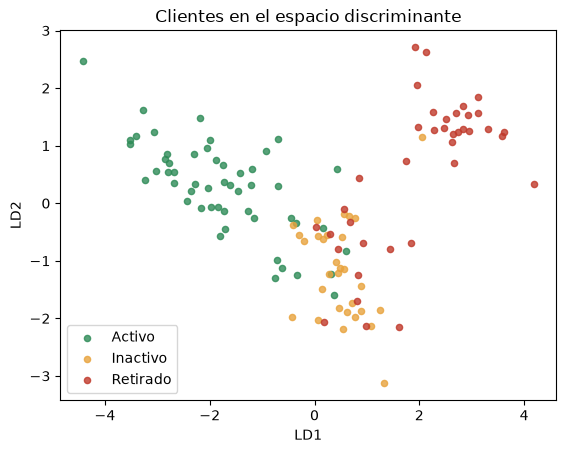

In [5]:
centroides = pd.DataFrame(Fd, columns=["LD1", "LD2"]).groupby(y.values).mean()
print(centroides.round(2))

colores = {"Activo": "#2E8B57", "Inactivo": "#E8A33D", "Retirado": "#C0392B"}
for cl, col in colores.items():
    m = (y == cl).values
    plt.scatter(Fd[m, 0], Fd[m, 1], s=20, color=col, label=cl, alpha=0.8)
plt.xlabel("LD1"); plt.ylabel("LD2"); plt.legend(); plt.title("Clientes en el espacio discriminante"); plt.show()

**¿Qué observar?**
- **LD1 (85,1 %)** se correlaciona con devoluciones (0,88), recencia (0,75) y, negativamente, con frecuencia (−0,85): es un eje de *desvinculación* que ordena Activo → Inactivo → Retirado.
- **LD2 (14,9 %)** separa a los inactivos; se asocia sobre todo con antigüedad (0,66), recencia (0,56) y visitas (−0,53).
- scikit-learn escala las funciones de otra manera que `MASS::lda`: los centroides difieren en el segundo decimal y los signos pueden invertirse. Para interpretar, usa la **matriz de estructura**.

## 3. Evaluación con validación cruzada

In [6]:
pred = cross_val_predict(modelo, X, y, cv=LeaveOneOut())
etiquetas = ["Activo", "Inactivo", "Retirado"]
print(pd.DataFrame(confusion_matrix(y, pred, labels=etiquetas), index=etiquetas, columns=etiquetas))
print(classification_report(y, pred, digits=3))
print("Exactitud balanceada:", round(balanced_accuracy_score(y, pred), 3))
print("Referencia (clase mayoritaria):", round((y == y.value_counts().idxmax()).mean(), 3))

          Activo  Inactivo  Retirado
Activo        42         9         1
Inactivo       2        27         1
Retirado       0        13        25
              precision    recall  f1-score   support

      Activo      0.955     0.808     0.875        52
    Inactivo      0.551     0.900     0.684        30
    Retirado      0.926     0.658     0.769        38

    accuracy                          0.783       120
   macro avg      0.810     0.789     0.776       120
weighted avg      0.845     0.783     0.794       120

Exactitud balanceada: 0.789
Referencia (clase mayoritaria): 0.433


**¿Qué observar?** Tasa global 78,3 % frente a 43,3 % de la clase mayoritaria; exactitud balanceada 78,9 %. Pero solo se reconoce el **65,8 % de los retirados** (13 se clasifican como inactivos), y la precisión de «Inactivo» es baja (55,1 %) porque allí caen esos errores. Si el objetivo es anticipar retiros, la regla debe mejorarse antes de usarla.

## 4. ¿Mejora el discriminante cuadrático?

In [7]:
pred_q = cross_val_predict(make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis()), X, y, cv=LeaveOneOut())
print("ADL  - aciertos:", round((pred == y).mean(), 3), "| balanceada:", round(balanced_accuracy_score(y, pred), 3))
print("ADC  - aciertos:", round((pred_q == y).mean(), 3), "| balanceada:", round(balanced_accuracy_score(y, pred_q), 3))

ADL  - aciertos: 0.783 | balanceada: 0.789
ADC  - aciertos: 0.767 | balanceada: 0.762


**¿Qué observar?** El cuadrático (76,7 %) no mejora al lineal y estima muchos más parámetros. Se mantiene el ADL y se documenta la decisión.

> **Fuga de información:** el ADL es invariante a cambios de escala, así que estandarizar fuera del pipeline no habría cambiado estos resultados. Con otros métodos (k vecinos, modelos regularizados) sí los sesga. El pipeline es la práctica correcta siempre.

### ✍️ Tu turno

Repite la validación cruzada con **probabilidades a priori iguales** (`LinearDiscriminantAnalysis(priors=[1/3, 1/3, 1/3])`). ¿Cómo cambian la tasa global, la exactitud balanceada y la tasa de aciertos de los retirados?

*Pista:* reemplaza el modelo dentro de `make_pipeline` y usa `classification_report`.

<details>
<summary><b>Ver una solución posible</b></summary>

```python
m2 = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(priors=[1/3, 1/3, 1/3]))
p2 = cross_val_predict(m2, X, y, cv=LeaveOneOut())
print(classification_report(y, p2, digits=3))
```

Con probabilidades a priori iguales, la tasa global es 79,2 % y la exactitud balanceada 80,4 %. Las tasas por grupo quedan en 78,8 % (Activo), 96,7 % (Inactivo) y 65,8 % (Retirado). Cambiar las probabilidades a priori desplaza las fronteras entre grupos: puede mejorar la detección de un grupo a costa de otro, y esa decisión depende del costo de cada error.

</details>

---
### Conecta con tu proyecto

Repite este flujo con la base de tu equipo. Guarda el cuaderno con salidas y verifica que se ejecute de principio a fin (*Entorno de ejecución → Reiniciar y ejecutar todo*) antes de entregarlo.

**Siguiente cuaderno:** integra los resultados de los cinco cuadernos en el informe final del proyecto *De los datos a las decisiones*.